Դիտարկվող տեքստը – ԱՇԽԱՐՀԱԳՐՈՒԹՅՈՒՆ 12: Հանրակրթական ավագ դպրոցի 12–րդ դասարանի դասագիրք / Մ. Մանասյան, Ա. Հովսեփյան, Ա. Պոտոսյան.— Եր.: «Զանգակ» հրատ., 2025.— 128 էջ: 

ARI միավորը՝ 10.75
Կրթ. աստիճանը՝ Տասներորդ դասարան             
ՎԻՃԱԿԱԳՐԱԿԱՆ ՏՎՅԱԼՆԵՐ
Գրանշանների քանակը՝ 185814 
Բառերի քանակը՝ 24691             
Եզակի բառերի քանակը՝ 6226, բառագործածման գործակիցը՝ 25.22%             
Բառի միջին երկարությունը՝ 7.53 նիշ
	բառի ակնկալվող միջին երկարությունը՝ 7.1 նիշ             
Նախադասության միջին երկարությունը՝ 13.37 բառ
	նախադասության ակնկալվող միջին երկարությունը՝ 13.2 բառ             
Առավել երկար 7 բառերը՝ «դաստիարակչական–հոգեբանական» (26 նիշ), «սոցիալ–տնտեսաաշխարհագրական» (26 նիշ), «էներգաարդյունավետությունը» (25 նիշ), «հասարակական–աշխարհագրական» (25 նիշ), «նավահանգստարդյունաբերական» (25 նիշ), «գազաջերմափոխանակությունը» (24 նիշ), «հասարակություն–բնություն» (24 նիշ)             
Առավել երկար նախադասությունը՝ «Գրեթե ամեն տարի այս կամ այն ծովի ջրերում նավթատար նավերի վթարների կամ ծ

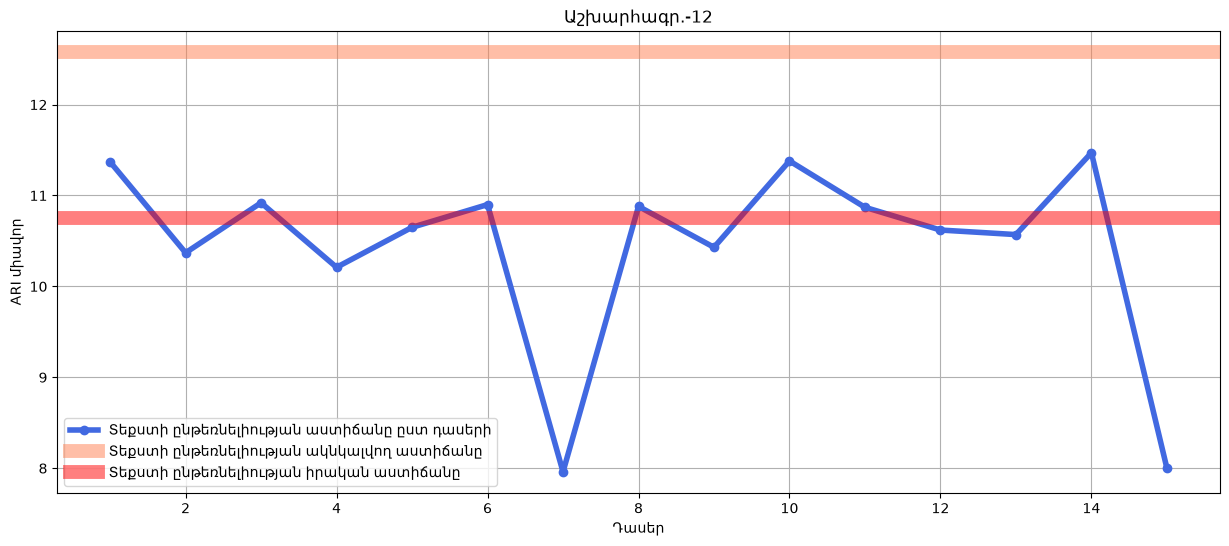

Դիտարկվող տեքստը – ՖԻԶԻԿԱ-7: Հանրակրթական դպրոցի 7-րդ դասարանի դասագիրք / Գ. Մելիքյան, Ս. Մաիլյան — Եր.: «Էդիթ Պրինտ», 2023.— 168 էջ: 

ARI միավորը՝ 7.36
Կրթ. աստիճանը՝ Յոթերորդ դասարան             
ՎԻՃԱԿԱԳՐԱԿԱՆ ՏՎՅԱԼՆԵՐ
Գրանշանների քանակը՝ 220610 
Բառերի քանակը՝ 37709             
Եզակի բառերի քանակը՝ 6113, բառագործածման գործակիցը՝ 16.21%             
Բառի միջին երկարությունը՝ 5.85 նիշ
	բառի ակնկալվող միջին երկարությունը՝ 6.4 նիշ             
Նախադասության միջին երկարությունը՝ 11.08 բառ
	նախադասության ակնկալվող միջին երկարությունը՝ 11.0 բառ             
Առավել երկար 7 բառերը՝ «t=t1+t2=s1/v1+s2/v2+s2/v1+s1/v2=s1+s21/v1+1/v2» (46 նիշ), «fա=f2-f1=ρhgh2s-ρhgh1s=ρhgh2-h1s=ρhghs» (38 նիշ), «p=p0+ρսնդgh=ρսնդgh+ρսնդgh=ρսնդgh+h» (34 նիշ), «fալ/fպ=ρալvg/ρպvg=ρալ/ρպ=2700» (29 նիշ), «արագություն=ճանապարհ/ժամանակ» (28 նիշ), «η=aօգ/aլր*100%=mgh/fl*100%» (26 նիշ), «m=spա–pն/g=ρսնդsh–h=13600» (25 նիշ)             
Առավել երկար նախադասությունը՝ «Օրինակ՝ մեծ երկարություններ չափելու համար օգտագործում են

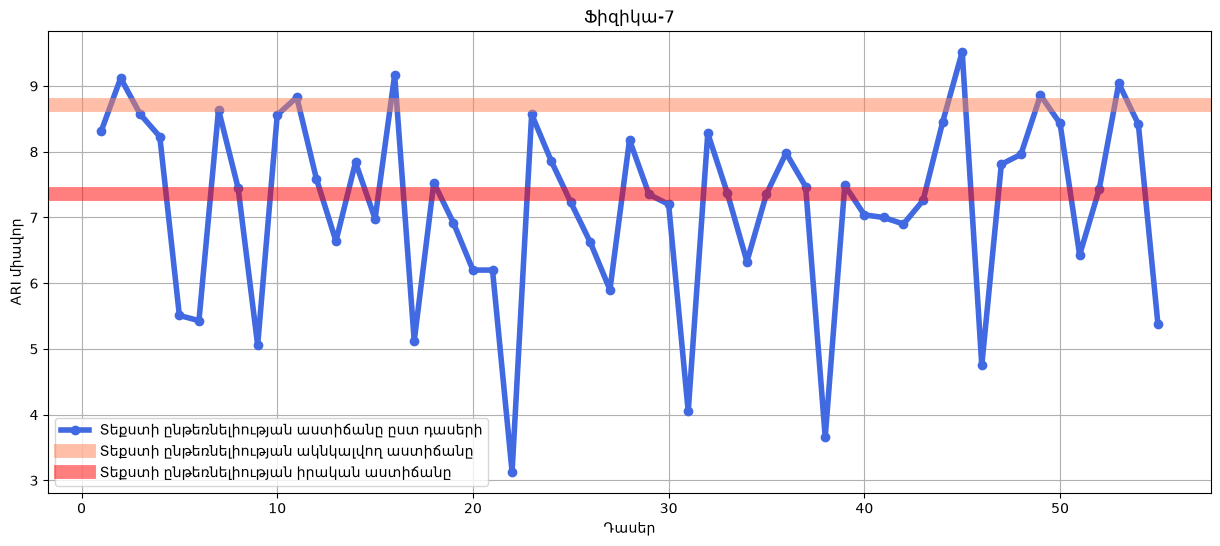

In [1]:
# Սա հայերէն տեքստերի դիւրընթեռնելութեան սանդղակի հաշուարկի յաւելուած է։
# Նաեւ տրամադրում է հայերէն տեքստերի վիճակագրական որոշ տուեալներ։

# Միացնում ենք մոդուլները
import os, re
import matplotlib.pyplot as plt
from collections import Counter

output_folder = "results/"
base_folder = "texts/"


# կազմում ենք աշխատանքային ծրարում եղած որոշակի տիպի նիշքերի անուների path[] ցուցակը (list)
def pathiks(base_folder):
    folder = base_folder
    ends = ['.txt', '.docx', '.pdf', '.html']
    paths = []
    filenames = []
    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.endswith(ends[0]) and not file.startswith(
                    '_'):  # ընտրում ենք text, docx, pdf -ից որեւէ մէկ նիշք՝ բացառելով թաքնուած նիշքերը (սկսվում են ~)
                paths.append(os.path.join(root, file))
                filenames.append(file)
    paths.sort()
    filenames.sort()
    return paths, filenames


# Each book is a folder inside texts/ (e.g. texts/geographia-12).
# Text files placed directly in texts/ are treated as one book.
def book_folders(base_folder):
    folders = []
    if any(f.endswith('.txt') and not f.startswith('_') for f in os.listdir(base_folder)
           if os.path.isfile(os.path.join(base_folder, f))):
        folders.append(base_folder)
    for name in sorted(os.listdir(base_folder)):
        path = os.path.join(base_folder, name)
        if os.path.isdir(path) and pathiks(path)[0]:
            folders.append(path)
    return folders


# Removes characters that are not allowed in file names (e.g. ":" on Windows).
def safe_filename(name, max_length=80):
    name = re.sub(r'[\\/:*?"<>|\n\r\t]', '_', str(name))
    return name.strip(' .')[:max_length].strip(' .')


def simple_parse(filename):
    """Նիշքի պարզ վերլուծում
      1. նիշքը կարդում ենք տող առ տող
      2. անջատում ենք մետատուեալները (# նշանով սկսուող տողերը) և տեքստը
      3. ըստ այդ տուեալների բանալի բառերով ստեղծում ենք բառարան
      4. կարող ենք մշակել տեքստը և մետատուեալները"""

    metadata = {}
    text_lines = []

    with open(filename, 'r', encoding='utf-8-sig') as f:  # utf-8-sig also reads files saved with a BOM
        for line in f:
            line = line.strip()
            if line.startswith('#') and '=' in line:
                # մետատուելների կորզում
                parts = line[1:].split('=', 1)
                if len(parts) == 2:
                    key = parts[0].strip()
                    value = parts[1].strip()
                    metadata[key] = value
            elif line and not line.startswith('#'):
                # հաւաքում ենք տեքստը
                text_lines.append(line)

    text = '\n'.join(text_lines) if text_lines else ''

    # արդիւնքների կառուցում
    result = {
        'doc_title_long': metadata.get('doc_title_long'),
        'doc_title_short': metadata.get('doc_title_short'),
        'doc_id': metadata.get('doc id'),
        'grade': metadata.get('index_est_score'),  # դիւրընթեռնելութեան ակնկալուող միաւորը մետատուեալներից
        'unit_title_long': metadata.get('newunit_title_long'),
        'unit_title_short': metadata.get('newunit_title_short'),
        'unit_id': metadata.get('newunit id'),
        'author_name': metadata.get('newauthor_name'),
        'author_id': metadata.get('newauthor id'),
        'lesson_title': metadata.get('newlesson_title'),
        'lesson_id': metadata.get('newlesson id'),
        'declared_text': metadata.get('text', ''),  # տեքստը մետատուեալներից
        'body_text': text  # մետատուեալներից յետոյ առկայ հիմնական տեքստը
    }

    # միացնում ենք ամբողջը տեքստը, եթէ մետատուեալների տեքստը հիմնական տեքստի մաս է
    result['full_text'] = result['declared_text'] + ('\n' + result['body_text'] if result['body_text'] else '')

    return result


def clean_text(text):
    # տեքստը մաքրում ենք աւելորդ կէտադրական նշաններից
    clean_text = re.sub(r"[)(—…'՛.․•՜«՛,:՝`՞։»]", "", text.lower())
    # հինգ և աւել տառանիշ ունեցող բառից ջնջում ենք թուերը (ենթադրաբար յղման թուերն են)
    clean_text = re.sub(r"([ա-ֆԱ-Ֆ]{5,})\d+", r"\1", clean_text)
    # կէտադրական նշանների ճիշտ տեղադրում
    clean_text = re.sub(r"([,։.])([Ա-Ֆա-ֆ])", r"\1 \2", clean_text)
    # թուին կպած տեքստը առանձնացնում ենք
    clean_text = re.sub(r"(\d+)([Ա-Ֆա-ֆ])", r"\1 \2", clean_text)
    # չաջակցուող իւնիկոդ նշանների ջնջում
    clean_text = clean_text.replace("\ufeff", "")

    # if fl=='yes':
    #     words = re.sub(r"([ա-ֆԱ-Ֆ]{5,})\d+", r"\1",
    #           text.replace('։', '').replace(',', '').
    #           replace('.', '').replace('՝', '')).split()

    return clean_text


def words_def(text):
    text_clean = clean_text(text)
    words = text_clean.split()
    words.sort()
    unic_words = set(words)
    unic_words = list(unic_words)
    unic_words.sort()

    # words_re = re.findall(r'\b\w+\b', text.lower())

    return words, unic_words


def sentences_list(text):
    # կէտադրական նշանների ճիշտ տեղադրում
    text = re.sub(r"([,։.])([Ա-Ֆա-ֆ])", r"\1 \2", text)
    text = re.sub(r"…([Ա-Ֆա-ֆ])", r"\1", text)
    sep = r'[:։!?\n]+'
    sentences = re.split(sep, text)
    sentences_c = [s.strip() for s in sentences if s.strip()]  # մաքրում ենք աւելորդ բացատներից և անորոշ նշաններից

    # դասաւորում ենք ըստ բառաքանակի
    sentences_sorted = sorted(sentences_c, key=lambda x: len(x.split()), reverse=True)
    return sentences, sentences_sorted


def score_grade(score):
    grade_map = {
        1: "Նախակրթարան",
        2: "Առաջին դասարան",
        3: "Երկրորդ դասարան",
        4: "Երրորդ դասարան",
        5: "Չորրորդ դասարան",
        6: "Հինգերորդ դասարան",
        7: "Վեցերորդ դասարան",
        8: "Յոթերորդ դասարան",
        9: "Ութերորդ դասարան",
        10: "Իններորդ դասարան",
        11: "Տասներորդ դասարան",
        12: "Տասնմեկերորդ դասարան",
        13: "Տասներկուերորդ դասարան",
        14: "Բուհական", ## երկու տարբերակ ունենք, կամ աիտի աւարտուի բուհականով, աւելի բարձր աստճան չունի այս ինդեքսը կամ նմանությամբ մինչև փորձագիտական
        15: "Հետբուհական",
        16: "Փորձագիտական"
    }

    match score: ## չպիտի՞ կլորացնենք մինչեւ կեսը, թէ հաշուում է՝ մեծ է նախորդից և փոքր կամ հաւասար է ընթացիկին - նախակրթարանը մէկ միաւոր է, առաջին դասարանը արդէն երկու միաւոր
        case n if n < 1:
            grade = 1
        case n if 1 <= n < 2:
            grade = 2
        case n if 2 <= n < 3:
            grade = 3
        case n if 3 <= n < 4:
            grade = 4
        case n if 4 <= n < 5:
            grade = 5
        case n if 5 <= n < 6:
            grade = 6
        case n if 6 <= n < 7:
            grade = 7
        case n if 7 <= n < 8:
            grade = 8
        case n if 8 <= n < 9:
            grade = 9
        case n if 9 <= n < 10:
            grade = 10
        case n if 10 <= n < 11:
            grade = 11
        case n if 11 <= n < 12:
            grade = 12
        case n if 12 <= n < 13:
            grade = 13
        case n if 13 <= n < 15:
            grade = 14
        case n if 15 <= n < 18:
            grade = 15
        case _:
            grade = 16
    return grade_map[grade], grade


# Returns the text report and the ARI score.
# grade is the expected score (index_est_score) used for the expected word and sentence lengths.
def ari_count(text, grade):
    # ARI = a × (characters / words) + b × (words / sentences) − c
    # lng selects the coefficient set; 3 is the Armenian formula −6.494 + 0.661·(W/S) + 1.116·(C/W)
    c = [21.5, 21.43, 11.8, 6.494]
    a = [3.8, 3.93, 1.9, 1.116]
    b = [0.54, 0.53, 0.49, 0.661]

    char_length = len(text) - text.count(' ') - text.count('\n')

    sentences, sentences_sorted = sentences_list(text)
    sentences_number = len(sentences)
    longest_sentence = f"«{sentences_sorted[0]}»։ ({len(sentences_sorted[0].split())} բառ)"

    words, unic_words = words_def(text)

    l_words = len(words)
    l_uni_words = len(unic_words)
    aver_word_length = round(char_length / l_words, 2)

    longest_words = sorted(unic_words, key=len, reverse=True)[:7]
    max_word = f"«{longest_words[0]}» ({len(longest_words[0])} նիշ)"
    for word in longest_words[1:]:
        max_word = max_word + f", «{word}» ({len(word)} նիշ)"

    aver_sentences_length = round(l_words / sentences_number, 2)

    lng = 3
    ari = round((a[lng] * aver_word_length) + (b[lng] * aver_sentences_length) - c[lng], 2)

    result_by_row = f'''\nARI միավորը՝ {ari}\nԿրթ. աստիճանը՝ {score_grade(ari)[0]} \
            \nՎԻՃԱԿԱԳՐԱԿԱՆ ՏՎՅԱԼՆԵՐ\nԳրանշանների քանակը՝ {char_length} \nԲառերի քանակը՝ {l_words} \
            \nԵզակի բառերի քանակը՝ {l_uni_words}, բառագործածման գործակիցը՝ {round(l_uni_words / l_words * 100, 2)}% \
            \nԲառի միջին երկարությունը՝ {aver_word_length} նիշ\n\tբառի ակնկալվող միջին երկարությունը՝ {awl_st[grade]} նիշ \
            \nՆախադասության միջին երկարությունը՝ {aver_sentences_length} բառ\n\tնախադասության ակնկալվող միջին երկարությունը՝ {asl_st[grade]} բառ \
            \nԱռավել երկար 7 բառերը՝ {max_word} \
            \nԱռավել երկար նախադասությունը՝ {longest_sentence}\n\n---------------------\n
                   '''
    return result_by_row, ari


# Տեքստը «տեղաւորենք» բառարանի մէջ։
def texts_mining(folder):
    data_unit_title = None
    unit_text = ''
    unit_text_list = []
    unit_name_list = []
    text_list = []

    for filename in pathiks(folder)[0]:
        data = simple_parse(filename)
        text_list.append(data['full_text'] + '\n')
        if data['unit_title_long'] == data_unit_title:
            unit_text = unit_text + data['full_text'] + '\n'
        else:
            if data_unit_title is not None:
                unit_name_list.append(data_unit_title)
                unit_text_list.append(unit_text)
            data_unit_title = data['unit_title_long']
            unit_text = data['full_text'] + '\n'

    unit_name_list.append(data_unit_title)
    unit_text_list.append(unit_text)

    return text_list, unit_name_list, unit_text_list


# Գրաֆիկական արտապատկերման ֆունկցիա։
# Ստանում է args_list-ը [x_lable, y_lable, title_label, x_data, y_data, average_length, average, file_path, x_limits]
def plot_result(args_list):
    x_lable, y_lable, title_label, x_data, y_data, average_length, average, file_path, x_limits = args_list

    color = 'red' if average_length >= average else 'green'

    fig, ax_main = plt.subplots(figsize=(15, 6))

    # Main plot
    ax_main.bar(x_data, y_data, linewidth=2, label='')
    ax_main.set_xlabel(x_lable)
    ax_main.set_ylabel(y_lable)
    ax_main.set_title(title_label)
    ax_main.grid(True, alpha=0.3)

    # Create inset in top right corner
    ax_inset = fig.add_axes([0.58, 0.57, 0.25, 0.25])  # [left, bottom, width, height]
    ax_inset.get_yaxis().set_ticks([])
    ax_inset.set_xlim(*x_limits)
    ax_inset.hlines(y=1, xmin=average_length, xmax=average, color=color, linewidth=8)
    ax_inset.axvline(x=average, color='blue', linestyle='-', label=f'Average: {average}', linewidth=2)
    ax_inset.set_title(f'Միջինի շեղումը՝ {round(average_length - average, 2)}')
    ax_inset.grid(True, alpha=0.3)

    fig.savefig(file_path, dpi=300, bbox_inches='tight', transparent=False)
    plt.close(fig)


# Reads the expected score from '# index_est_score = 12'.
# Returns None if it is missing or is not a whole number from 0 to 14.
def parse_grade(value):
    try:
        grade = int(str(value).strip())
    except ValueError:
        return None
    return grade if 0 <= grade < len(awl_st) else None


# Converts a list of lengths to x values and percentages.
def length_frequencies(lengths):
    len_frq_dict = Counter(lengths)
    total = sum(len_frq_dict.values())
    x_data = list(len_frq_dict.keys())  # x տուեալներ
    y_data = [count / total * 100 for count in len_frq_dict.values()]  # y տուեալներ (%)
    return x_data, y_data


awl_st = [4.2, 4.7, 4.9, 5.2, 5.4, 5.5, 5.9, 6.2, 6.4, 6.6, 6.7, 6.9, 7.1, 7.2, 7.6]
asl_st = [7.0, 7.9, 8.4, 8.8, 9.2, 9.7, 10.1, 10.6, 11.0, 11.4, 11.9, 12.3, 13.2, 15.0, 17.6]
ari_st = [-1.8, 0.58, 1.61, 2.96, 3.94, 4.6, 6.32, 7.73, 8.71, 9.68, 10.34, 11.32, 12.58, 13.98, 16.96]

x_lable_list = ["Բառի երկարությունը", "Նախադասության երկարությունը"]
y_lable_list = ["Բառերի քանակը (%)", "Նախադասությունների քանակը (%)"]


# Calculates the results of one book and writes them to its own folder in results/.
def process_book(book_folder):
    book_name = os.path.basename(os.path.normpath(book_folder))
    book_output = os.path.join(output_folder, book_name) if os.path.normpath(book_folder) != os.path.normpath(
        base_folder) else output_folder
    os.makedirs(book_output, exist_ok=True)

    data_unit_title = None
    unit_text = ''
    unit_text_list = []
    unit_name_list = []
    all_result = ''
    x = []
    data = None
    book_grade = None

    for filename in pathiks(book_folder)[0]:

        file_data = simple_parse(filename)
        grade = parse_grade(file_data['grade'])
        if grade is None:
            if book_grade is None:
                print(f"Skipped {filename}: no valid '# index_est_score = ...' line (expected a number from 0 to 14, found {file_data['grade']!r})")
                continue
            print(f"Warning: {filename} has no valid '# index_est_score = ...' line, using {book_grade} from the previous lessons")
            grade = book_grade
        if not file_data['full_text'].split():
            print(f"Skipped {filename}: no text")
            continue
        data = file_data
        text = data['full_text']
        if book_grade is None:
            book_grade = grade
        char_length = len(text) - text.count(' ') - text.count('\n')

        if data['unit_title_long'] == data_unit_title:
            unit_text = unit_text + data['full_text'] + '\n'
        else:
            if data_unit_title is not None:
                unit_name_list.append(data_unit_title)
                unit_text_list.append(unit_text)
            data_unit_title = data['unit_title_long']
            unit_text = data['full_text'] + '\n'

        result_by_row, ari = ari_count(text, grade)

        all_result = all_result + f"Բաժին – {data['unit_title_long']}\
\nԴաս – {data['lesson_title']} \nՀեղինակ – {data['author_name']} \n{result_by_row}"

        text_name = data['lesson_title']
        file_stem = os.path.splitext(os.path.basename(filename))[0]
        plot_name = os.path.join(book_output, safe_filename(f"{file_stem}_{text_name}"))

        words, unic_words = words_def(text)
        l_words = len(words)
        awl = round(char_length / l_words, 2)

        sentences, sentences_sorted = sentences_list(text)
        sentences_number = len(sentences)
        asl = round(l_words / sentences_number, 2)

        awl_expected = awl_st[grade]
        asl_expected = asl_st[grade]

        title_lable = [
            f"{text_name}, {data['author_name']} \nԲառերի հաճախականությունը ըստ նիշերի  քանակի, \nմիջին արժեքը՝ {awl}, ակնկալվողը՝ ~{awl_expected}",
            f"{text_name}, {data['author_name']} \nՆախադասությունների հաճախականությունը ըստ բառերի  քանակի, \nմիջին արժեքը՝ {asl}, ակնկալվողը՝ ~{asl_expected}"]

        # word length chart
        list_word_length = [len(word) for word in unic_words]
        x_data, y_data = length_frequencies(list_word_length)
        plot_args = [x_lable_list[0], y_lable_list[0], title_lable[0], x_data, y_data, awl, awl_expected,
                     plot_name + "_word.png", (3, 9)]
        plot_result(plot_args)

        # sentence length chart
        list_sentence_length = [len(sentence.split()) for sentence in sentences_sorted]
        x_data, y_data = length_frequencies(list_sentence_length)
        plot_args = [x_lable_list[1], y_lable_list[1], title_lable[1], x_data, y_data, asl, asl_expected,
                     plot_name + "_sent.png", (0, max(20, asl, asl_expected) + 2)]
        plot_result(plot_args)

        x.append(ari)

    if data is None:
        return

    all_result = "\nԸՍՏ ԴԱՍԵՐԻ\n\n------*****------\n" + all_result

    unit_name_list.append(data_unit_title)
    unit_text_list.append(unit_text)

    units_result = ''
    for i in range(len(unit_name_list)):
        unit_result, unit_ari = ari_count(unit_text_list[i], book_grade)
        units_result = units_result + f"Բաժինը՝ {unit_name_list[i]}\n{unit_result}"
    all_result = units_result + all_result

    all_result = "\nԸՍՏ ԲԱԺԻՆՆԵՐԻ\n------*****------\n" + all_result

    book_text = '\n'.join(unit_text_list)
    books_ari, book_ari = ari_count(book_text, book_grade)
    all_result = f"Դիտարկվող տեքստը – {data['doc_title_long']} \n{books_ari}" + all_result

    print(all_result)

    fig = plt.figure(figsize=(15, 6))
    plt.title(data['doc_title_short'])
    plt.xlabel('Դասեր')
    plt.ylabel('ARI միավոր')
    y = [i for i in range(1, len(x) + 1)]
    plt.grid(True)
    plt.plot(y, x, 'o-', label=f"Տեքստի ընթեռնելիության աստիճանը ըստ դասերի", color='royalblue', linewidth=4)
    plt.axhline(ari_st[book_grade], color='coral', linestyle='-', label=f"Տեքստի ընթեռնելիության ակնկալվող աստիճանը",
                linewidth=10, alpha=0.5)
    plt.axhline(book_ari, color='red', linestyle='-', label=f"Տեքստի ընթեռնելիության իրական աստիճանը", linewidth=10,
                alpha=0.5)
    plt.legend()
    plt.savefig(os.path.join(book_output, 'by_lesson.png'), dpi=300, bbox_inches='tight', transparent=False)
    plt.show()
    plt.close(fig)

    with open(os.path.join(book_output, "_արդիւնք.txt"), "w", encoding="utf-8") as file:
        file.write(all_result)


os.makedirs(output_folder, exist_ok=True)

for book_folder in book_folders(base_folder):
    process_book(book_folder)